In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

#ımport models
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

#plot style for visualizations

#set background of the plot white and with a grid
sns.set(style="whitegrid")
#make all future plots 10x6
plt.rcParams['figure.figsize'] = (10, 6)

#load the dataset
try:
    df = pd.read_csv("water_risk_dataset.csv")
    print("Dataset loaded successfully.")
    
except FileNotFoundError:
    print("file not found")

Dataset loaded successfully.


# CENG 463 HW 1– Water Resource Risk Classification
**Start Date:**  
**Due Date:** Month Dayth, 2026

## Dataset Overview
The dataset utilized in this assignment originates from the World Resources Institute (WRI) – Aqueduct Water Risk Atlas. It provides country-level indicators describing key hydrological and environmental factors, which are listed in the table below. The objective is to classify each country into a Water Resource Risk Category (0-4) using these indicators. Students are also expected to create two derived features — Composite Water Stress Index (CWSI) and Seasonal–Flood Interaction (SFI).

| Feature | Description |
|---------|-------------|
| gid_0 | Country Code |
| bws_score | Baseline Water Stress |
| gtd_score | Groundwater Depletion |
| drr_score | Drought Risk |
| rfr_score | River Flood Risk |
| sev_score | Seasonal Variability |
| w_awr_def_tot_cat | Target: Water Risk Category (0-4) |


## 1. Feature Engineering (35 pts)
Students are expected to create two new features based on the existing indicators:

1. **Composite Water Stress Index (CWSI):**
   CWSI combines baseline water stress, groundwater depletion, and drought risk.
   Formula: CWSI = 0.5 × bws_score + 0.3 × gtd_score + 0.2 × drr_score

2. **Seasonal–Flood Interaction (SFI):**
   SFI represents interaction between seasonal variability and river flood risk.
   Formula: SFI = sev_score × rfr_score


In [49]:
# TODO: Create CWSI and SFI features
#create CWSI feature
df['CWSI'] = (0.5 * df['bws_score'] +
              0.3 * df['gtd_score'] +
              0.2 * df['drr_score'])
#create SFI feature
df['SFI'] = (df['sev_score'] * df['rfr_score'])

#We are simply constructing 2 new features, using the old features. Composite Water Stress Index (CWSI) and
#Seasonal–Flood Interaction (SFI). How they are computed is given in the homework instructions and we have simply implemented it.

#Discussion for Part 1: Feature Engineering
print("\nDiscussion 1: Feature Engineering")
print("We successfully created two derived features to support the model's predictive power:")
print("1. Composite Water Stress Index (CWSI): Represents overall water pressure combining baseline stress, groundwater depletion, and drought risk.")
print(f"   - Sample values (first 3 rows): {df['CWSI'].head(3).tolist()}")
print("2. Seasonal-Flood Interaction (SFI): Represents the combined risk of seasonal variability and river flood.")
print(f"   - Sample values (first 3 rows): {df['SFI'].head(3).tolist()}")
print("These new features provide a more total view of water risk than individual parameters alone.")


Discussion 1: Feature Engineering
We successfully created two derived features to support the model's predictive power:
1. Composite Water Stress Index (CWSI): Represents overall water pressure combining baseline stress, groundwater depletion, and drought risk.
   - Sample values (first 3 rows): [1.0346496503044598, 1.7265921968224953, 0.8379072395172461]
2. Seasonal-Flood Interaction (SFI): Represents the combined risk of seasonal variability and river flood.
   - Sample values (first 3 rows): [3.15037457125874, 5.182896305284892, 0.09489561492866656]
These new features provide a more total view of water risk than individual parameters alone.


## 2. Model Training & Evaluation (40 pts)
Train five classification models: Random Forest, SVM, KNN, Gaussian Naive Bayes, Logistic Regression.

*Hint: Use scaled data for SVM, KNN, Logistic Regression.*

In [50]:
# TODO: Split data into features X and target y
# TODO: Train models and evaluate accuracy
# TODO: Prepare evaluation table

#gid_0 feature is country code and it is not contributing to any ML model
#including it is dangerous because our selected model can memorize a country code's target
#to some value and always remember it instead of learning patterns.
#exclude gid_0 feature which can led to overfitting and exclude target feature
X = df.drop(['gid_0', 'w_awr_def_tot_cat'], axis=1)

#send targets to y
y = df['w_awr_def_tot_cat']

#train test split X and y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#print training and testing set shapes for both X and y
#features gid_0 and w_awr_def_tot_cat excluded
#features CWSI and SFI added to data frame
#so there should be total of 7 features in a single data point
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing set shape: X_test={X_test.shape}, y_test={y_test.shape}")

#initializing Random Forest Model
model_rf = RandomForestClassifier(random_state=42)

#using pipeline for scaling the data and initializing models
#to prevent memory leaks

#scale data and initialize Support Vector Machine model
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])

#scale data and initialize K Nearest Neighbour model
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

#initializing Gaussian Naive Bayes Model
model_gnb = GaussianNB()

#scale data and initialize Logistic Regression model
pipe_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=42, max_iter=1000))
])

#dictionary of models
models = {
    'Random Forest': model_rf,
    'SVM': pipe_svm,
    'KNN': pipe_knn,
    'Gaussian Naive Bayes': model_gnb,
    'Logistic Regression': pipe_logreg
}

#initialize a dictionary to store model's base results
models_base_results = {}

print("\n Models Base Results :")

for name, model in models.items():
    print(f"Training {name} model")
    model.fit(X_train, y_train)#train the model
    y_predict = model.predict(X_test)#predict for test data
    accuracy = accuracy_score(y_test, y_predict)#compute accuracy of test data
    models_base_results[name] = accuracy#send accuracy to dictionary for further use
    print(f"accuracy for model is: {accuracy:.4f}\n")

#evaluation table
#send models_base_results to a data frame
base_results_df = pd.DataFrame.from_dict(models_base_results, orient='index',columns=['Base Accuracy'])
print("\n-----Evaluation Table-----")
#sort the results and print
print(base_results_df.sort_values(by='Base Accuracy', ascending=False))

#Discussion for Part 2: Baseline Model Performance

#retrieve best and worst performing models from baseline results
best_baseline_model = max(models_base_results, key=models_base_results.get) #retrieve the model name with the highest accuracy
best_baseline_score = models_base_results[best_baseline_model] #retrieve the accuracy score of the best model
worst_baseline_model = min(models_base_results, key=models_base_results.get) #retrieve the model name with the lowest accuracy

print("\nDiscussion 2: Baseline Model Performance")
print(f"We trained five classification models. The results show that:")
print(f"1. The best performing model out-of-the-box is **{best_baseline_model}** with an accuracy of **{best_baseline_score:.4f}**.")
print(f"2. The lowest performing model was {worst_baseline_model}.")
print(f"3. Suitability: The strong performance of {best_baseline_model} suggests that the dataset features have predictive power "
      f"{'that captures non-linear relationships well' if 'Random Forest' in best_baseline_model else ' '}.")
#we assume that our best model is Random Forest but just in case it is not we added a conditional statement



Training set shape: X_train=(3644, 7), y_train=(3644,)
Testing set shape: X_test=(911, 7), y_test=(911,)

 Models Base Results :
Training Random Forest model
accuracy for model is: 0.9122

Training SVM model
accuracy for model is: 0.7651

Training KNN model
accuracy for model is: 0.8035

Training Gaussian Naive Bayes model
accuracy for model is: 0.6048

Training Logistic Regression model
accuracy for model is: 0.6729


-----Evaluation Table-----
                      Base Accuracy
Random Forest              0.912184
KNN                        0.803513
SVM                        0.765093
Logistic Regression        0.672887
Gaussian Naive Bayes       0.604830

Discussion 2: Baseline Model Performance
We trained five classification models. The results show that:
1. The best performing model out-of-the-box is **Random Forest** with an accuracy of **0.9122**.
2. The lowest performing model was Gaussian Naive Bayes.
3. Suitability: The strong performance of Random Forest suggests that the da

## 3. Hyperparameter Optimization (20 pts)
Tune each model using GridSearchCV with 5-fold CV.
Compare baseline and tuned results and report improvements.
Identify the model with highest tuned performance.

Hint: Use accuracy as scoring metric. Add classification report.

In [ ]:
# [TODO: Define parameter grids for each model]

from sklearn.model_selection import GridSearchCV #for hyperparameter tuning
from sklearn.metrics import classification_report #for detailed classification report

#set parameters 
#for pipelines parameters must be named like name of the step + "__"
#example 'C' parameter of the 'svm' step in the pipeline: 'svm__C'
random_forest_params = {
    'n_estimators': [50, 100, 200], #number of trees in the forest
    'max_depth': [None, 10, 20, 30], #maximum depth of the tree
    'min_samples_split': [2, 5, 10] #minimum number of samples required to split an internal node
}

svm_params = {
    'svm__C': [0.1, 1, 10, 100], #regularization parameter of the SVM
    'svm__kernel': ['linear', 'rbf'], #kernel type to be used in the algorithm: linear or radial basis function
    'svm__gamma': ['scale', 'auto'] #gamma parameter for kernel
}

knn_params = {
    'knn__n_neighbors': [3, 5, 7, 9, 11], #number of neighbors to use
    'knn__weights': ['uniform', 'distance'], #weight function used in prediction
    'knn__metric': ['euclidean', 'manhattan'] #distance metric 
}

gnb_params = {
    'var_smoothing': np.logspace(0, -9, num=100) #variance smoothing is a calculation stability parameter
                                                 #np.logspace generates numbers spaced evenly on a log scale
}

logreg_params = {
    'logreg__C': [0.01, 0.1, 1, 10, 100], #C is also regularization parameter, smaller C means higher regularization
    'logreg__solver': ['lbfgs', 'liblinear'] #optimization algorithm to use: lbgfs is good for small datasets,
                                             #liblinear supports l1 penalty if needed
}

#map models to their parameters
model_grids = {
    'Random Forest': (model_rf, random_forest_params),
    'SVM': (pipe_svm, svm_params),
    'KNN': (pipe_knn, knn_params),
    'Gaussian Naive Bayes': (model_gnb, gnb_params),
    'Logistic Regression': (pipe_logreg, logreg_params)
}

# [TODO: Perform GridSearchCV and compare results]

#execution of GridSearchCV

#initialize dictionaries to store tuned results and best estimators
tuned_results = {}
best_estimators = {}

print("Executing Hyperparameter Optimization: \n") #print that optimization is starting

#loop for each model and its parameters to execute GridSearchCV
for name, (model, grid) in model_grids.items():
    print(f"Tuning {name}: ") #specify which model is being tuned
    
    #initialize GridSearchCV
    #cv=5 means 5-fold cross-validation
    #n_jobs=-1 uses all available processors to speed it up
    grid_search = GridSearchCV(estimator=model, param_grid=grid, cv=5, scoring='accuracy', n_jobs=-1)
    
    #fit to training data to GridSearchCV's initialized model
    grid_search.fit(X_train, y_train)
    
    #get best parameters and estimator
    best_params = grid_search.best_params_ #gets the best parameters found during tuning
    best_model = grid_search.best_estimator_ #gets the model object with the best parameters
    best_estimators[name] = best_model #save that model object to dictionary for further use
    
    #test the best model on test set
    y_pred_tuned = best_model.predict(X_test) #predict test set with the best model found above
    tuned_acc = accuracy_score(y_test, y_pred_tuned) #get the tuned accuracy from best model predictions
    tuned_results[name] = tuned_acc #save tuned accuracy to dictionary for further use
    
    print(f"  Best Params: {best_params}") #print best parameters found
    print(f"  Tuned Accuracy: {tuned_acc:.4f}") #print tuned accuracy
    print("-" * 30) #separator for readability
    
    #classification report for the best model
    print(f"Classification Report for {name} (Tuned):\n") #print classification report header
    print(classification_report(y_test, y_pred_tuned)) #print classification report
    print("=" * 50 + "\n") #separator for readability

#compare baseline vs. tuned results
print("--- Improvement Analysis ---") #print results comparison header

#create a pandas data frame to compare baseline and tuned results
results_comparison = pd.DataFrame({
    'Baseline Accuracy': pd.Series(models_base_results), #retrieve baseline accuracies from step 2
    'Tuned Accuracy': pd.Series(tuned_results) #retrieve tuned accuracies from step 3
})
#calculate improvement (difference between tuned and baseline accuracies)
results_comparison['Improvement'] = results_comparison['Tuned Accuracy'] - results_comparison['Baseline Accuracy']

#display sorted results
print(results_comparison.sort_values(by='Tuned Accuracy', ascending=False))

#identify and print the best model
best_model_name = results_comparison['Tuned Accuracy'].idxmax()
print(f"\nThe model with the highest tuned performance is: {best_model_name} "
      f"with an accuracy of {results_comparison.loc[best_model_name, 'Tuned Accuracy']:.4f}")

#Discussion for Part 3: Hyperparameter Tuning Analysis
print("\n" + "="*50) #separator for readability
print("Discussion 3: Hyperparameter Tuning Analysis")
print("="*50) #separator for readability
print("We optimized each model using GridSearchCV with 5-fold cross-validation.\n")

#comparison of baseline and tuned models
max_improvement_model = results_comparison['Improvement'].idxmax() #model with maximum improvement
max_imp_val = results_comparison.loc[max_improvement_model, 'Improvement'] #value of maximum improvement

print("Comparison of Results:")
print(f"-The model that benefited most from tuning was **{max_improvement_model}**, "
      f"improving by {max_imp_val:.4f}.")
print("-This suggests that the default parameters for this model were not optimal for the Water Risk dataset.\n")

#discussion of parameter optimization
print("Parameter Optimization Effects:")
print("-Tuning allowed us to find the optimal balance between bias and variance")
print("-By systematically searching the parameter grid we ensured the models are not overfitting to the training data.\n")

# 3. Best Model Conclusion
print("Conclusion:")
print(f"-The **{best_model_name}** is identified as the best overall model with a tuned accuracy of {results_comparison.loc[best_model_name, 'Tuned Accuracy']:.4f}.")



Executing Hyperparameter Optimization: 

Tuning Random Forest: 
  Best Params: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
  Tuned Accuracy: 0.9122
------------------------------
Classification Report for Random Forest (Tuned):

              precision    recall  f1-score   support

         0.0       0.97      0.97      0.97       147
         1.0       0.88      0.93      0.90       174
         2.0       0.88      0.83      0.86       174
         3.0       0.89      0.90      0.89       193
         4.0       0.95      0.94      0.94       223

    accuracy                           0.91       911
   macro avg       0.91      0.91      0.91       911
weighted avg       0.91      0.91      0.91       911


Tuning SVM: 
  Best Params: {'svm__C': 100, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
  Tuned Accuracy: 0.8167
------------------------------
Classification Report for SVM (Tuned):

              precision    recall  f1-score   support

         0.0       0.8

## 4. Feature Importance Analysis (5 pts)
Choose one model and analyze feature importance. Present most influential features in a table and bar chart.

Using the tuned Random Forest model from Step 3.

-----Feature Importances-----
     Feature  Importance
5       CWSI    0.274392
0  bws_score    0.171225
2  drr_score    0.161309
1  gtd_score    0.142603
6        SFI    0.090008
4  rfr_score    0.082425
3  sev_score    0.078039


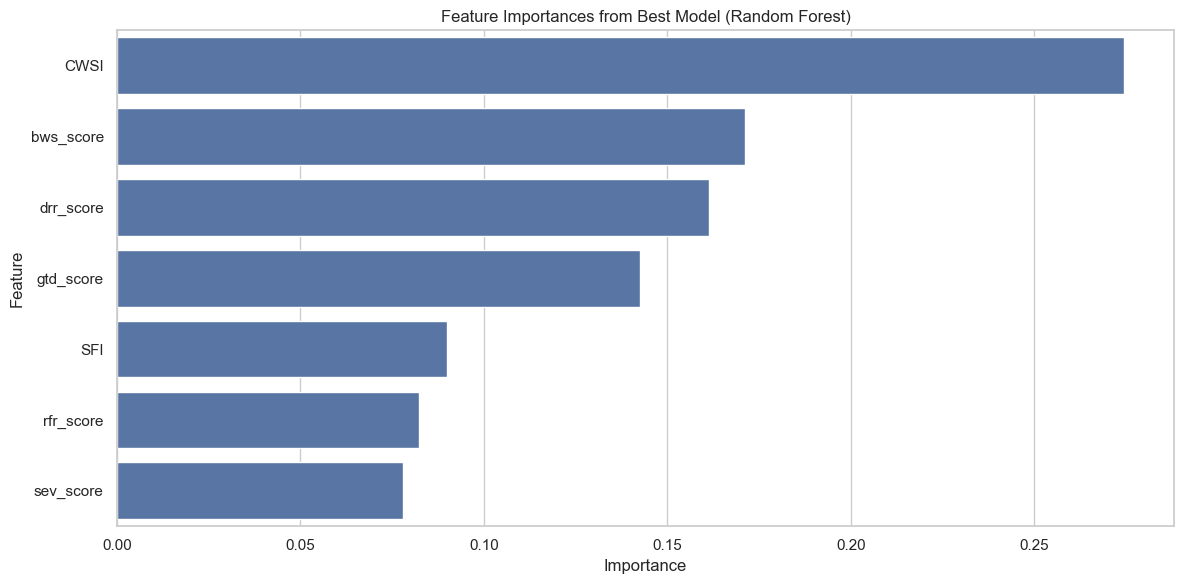

The top 5 most influential features are: 
1. CWSI: 0.2744
2. bws_score: 0.1712
3. drr_score: 0.1613
4. gtd_score: 0.1426
5. SFI: 0.0900

Analysis:
-Primary Driver: The fact that '**CWSI**' is the top feature confirms that baseline water stress, groundwater depletion, and drought risk combined is the most critical factor in determining risk.
-Least Influential: Features like **sev_score** contributed the least, suggesting they do not strongly differentiate between risk categories.

       FINAL MODEL COMPARISON
                      Baseline Accuracy  Tuned Accuracy  Improvement  Rank
Random Forest                  0.912184        0.912184     0.000000   1.0
KNN                            0.803513        0.885840     0.082327   2.0
SVM                            0.765093        0.816685     0.051592   3.0
Logistic Regression            0.672887        0.670692    -0.002195   4.0
Gaussian Naive Bayes           0.604830        0.622393     0.017563   5.0

Final Conclusion
Based on this an

In [ ]:
# TODO: Select your best model (e.g., Random Forest)
#let's use best tuned model which is random forest for us from step 3
target_model_name = 'Random Forest' #specify the target model name

if target_model_name in best_estimators:
    best_model = best_estimators[target_model_name] #retrieve the best model object
    print(f"Using the tuned {target_model_name} model from Step 3.")#confirm the selected model
else:
    #security check in case the model name is not found
    print(f"Error: {target_model_name} not found in best estimators.")
    #let's reinitialize a new random forest model as a fallback
    best_model = RandomForestClassifier(random_state=42)
    best_model.fit(X_train, y_train) #train the new model   


# TODO: Train the model on the training data if not already trained
#already trained above

# TODO: Calculate feature importances
#feature importances from the trained random forest model
feature_importances = best_model.feature_importances_

# TODO: Create a table of features sorted by importance
feature_names = X.columns #get feature names from training data

#create a data frame for feature importances
importance_df = pd.DataFrame({'Feature': feature_names,
                            'Importance': feature_importances})

#sort the data frame by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

#display feature importances
print("\n-----Feature Importances-----")
print(importance_df)


# TODO: Plot a bar chart of feature importances
#plot feature importances using seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importances from Best Model (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# TODO: Optional: Comment on top 3-5 most influential features
print(f"The top 5 most influential features are: ")
      
#the top 5 most influential features according to the Random Forest model are:
top_features = importance_df.head(5)

#enumarate to get ranking 
#and iterrows() -> i, row to unpack our data frame rows which gives us index and row data for each row
#we will just use row and
#ranking from enumerate instead of i from iterrows()
for ranking, (i, row) in enumerate(top_features.iterrows()):
    print(f"{ranking + 1}. {row['Feature']}: {row['Importance']:.4f}")


#Discussion for Part 4: Feature Importance Analysis
top_feature_name = importance_df.iloc[0]['Feature'] #get the name of the most important feature
top_5_list = top_features['Feature'].tolist() #list of top 5 feature names

print("\nAnalysis:")
#Analyze the significance of top feature
#we know that CWSI is the most important feature from our feature engineering step but just in case we added bws_score too
if top_feature_name in ['CWSI', 'bws_score']:
    print(f"-Primary Driver: The fact that '**{top_feature_name}**' is the top feature confirms that baseline water stress, groundwater depletion, and drought risk combined is the most critical factor in determining risk.")

#print least influential feature
print(f"-Least Influential: Features like **{importance_df.iloc[-1]['Feature']}** contributed the least, suggesting they do not strongly differentiate between risk categories.")


#final conclusion
print("\n" + "="*40) #separator for readability
print("       FINAL MODEL COMPARISON") 
print("="*40) #separator for readability

#final summary table with using results from previous steps
final_table = results_comparison.copy() #copy results comparison from step 3
final_table['Rank'] = final_table['Tuned Accuracy'].rank(ascending=False) #rank models by tuned accuracy
print(final_table.sort_values('Rank')) #display final table sorted by rank

best_tuned_score = results_comparison['Tuned Accuracy'].max() #retrieve the best tuned score

print(f"\nFinal Conclusion")
print(f"Based on this analysis the **{best_model_name}** is the best model for this dataset.")
print(f"1.Accuracy: it achieved the highest testing accuracy of {best_tuned_score:.4f}.")
print(f"2.Feature Effectiveness: It effectively utilizes key features like {top_feature_name} to predict Water Resource Risk Categories.")
print("This model implements the best balance of generalization and predictive power for this dataset.")

